Se encontraron 9 archivos mensuales dentro del ZIP.

✨ ¡Dataset consolidado con éxito!
Dimensiones totales: 24718 filas, 25 columnas
                                    tramite_tipo tramite_fecha  \
0  DENUNCIA DE ROBO O HURTO / RETENCION INDEBIDA    2026-01-02   
1                       COMUNICACIÓN DE RECUPERO    2026-01-02   

  fecha_inscripcion_inicial  registro_seccional_codigo  \
0                2016-01-25                       4035   
1                1993-02-12                       4038   

  registro_seccional_descripcion registro_seccional_provincia  \
0                  CORDOBA Nº 05                      Córdoba   
1                  CORDOBA Nº 07                      Córdoba   

  automotor_origen  automotor_anio_modelo automotor_tipo_codigo  \
0     Protocolo 21                 2016.0                  82.0   
1         Nacional                 1993.0                  22.0   

  automotor_tipo_descripcion  ... automotor_uso_descripcion  \
0       PICK-UP CABINA DOBLE  ..

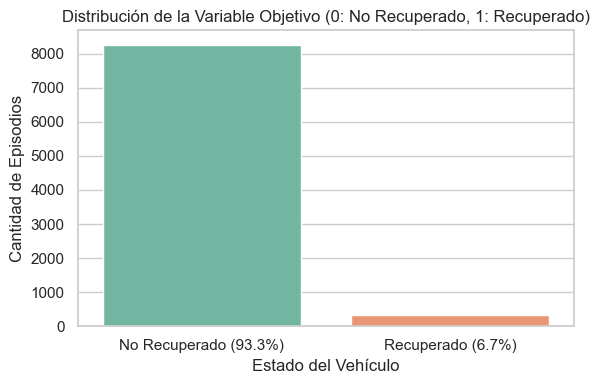

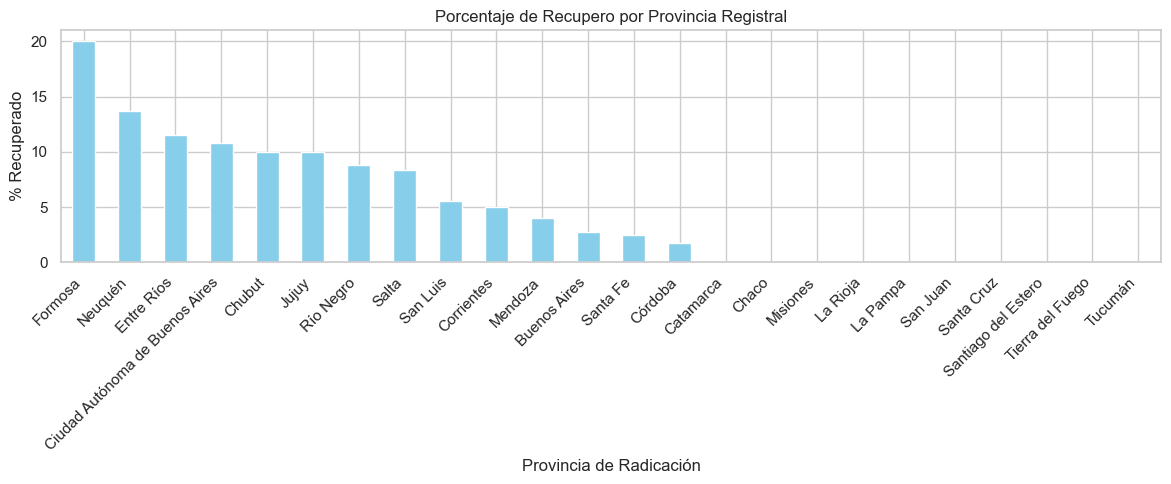


✅ Dataset procesado guardado exitosamente. Total filas listas para modelar: 8417


In [12]:
# ==============================================================================
# 1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Estilo visual de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# ==============================================================================
# 2. CARGA DE DATOS CRUDOS DESDE LA CARPETA RAW
# ==============================================================================
# Carga del CSV utilizando la ruta correcta y la columna de fecha real ('tramite_fecha')
#df_raw = pd.read_csv('../data/raw/dnrpa-robos-recuperos-autos-202609.csv', parse_dates=['tramite_fecha'])

#print(f"Dimensiones iniciales: {df_raw.shape[0]} filas, {df_raw.shape[1]} columnas")
#print("\n--- Vista preliminar de datos ---")
#print(df_raw.head(2))

# Ruta al archivo zip consolidado en la carpeta raw
#ruta_zip = '../data/raw/dnrpa-robos-recuperos-autos-2026.zip'

# Leer el CSV comprimido directamente (ajusta el nombre del archivo interno si es necesario)
#df_raw = pd.read_csv(ruta_zip, compression='zip', parse_dates=['tramite_fecha'])

#print(f"Dimensiones cargadas desde el ZIP: {df_raw.shape[0]} filas, {df_raw.shape[1]} columnas")
#print(df_raw.head(2))
import zipfile


ruta_zip = '../data/raw/dnrpa-robos-recuperos-autos-2026.zip'

lista_dfs = []

# Abrir el archivo ZIP y leer cada CSV interno de forma automatizada
with zipfile.ZipFile(ruta_zip, 'r') as z:
    # Filtrar solo los archivos que terminan en .csv
    archivos_csv = [f for f in z.namelist() if f.endswith('.csv')]
    
    print(f"Se encontraron {len(archivos_csv)} archivos mensuales dentro del ZIP.")
    
    for archivo in archivos_csv:
        with z.open(archivo) as f:
            # Leer el CSV y agregarlo a la lista
            df_temp = pd.read_csv(f, parse_dates=['tramite_fecha'], low_memory=False)
            lista_dfs.append(df_temp)

# Consolidar todos los meses en un único DataFrame
df_raw = pd.concat(lista_dfs, ignore_index=True)

print(f"\n✨ ¡Dataset consolidado con éxito!")
print(f"Dimensiones totales: {df_raw.shape[0]} filas, {df_raw.shape[1]} columnas")
print(df_raw.head(2))


# ==============================================================================
# 3. LIMPIEZA, HORIZONTE TEMPORAL (180 DÍAS) Y CONSTRUCCIÓN DE LA VARIABLE OBJETIVO
# ==============================================================================
# A. Ordenar por ID o identificador de vehículo y fecha del trámite
# Nota: Como el dataset usa 'registro_seccional_codigo' u otros campos, ordenamos por trámite fecha
df_sorted = df_raw.sort_values(by=['tramite_fecha']).copy()

# B. Definir la fecha límite para el horizonte temporal de 6 meses (180 días)
FECHA_CORTE_DATASET = df_sorted['tramite_fecha'].max()
HORIZONTE_DIAS = 180
FECHA_LIMITE_DENUNCIA = FECHA_CORTE_DATASET - pd.Timedelta(days=HORIZONTE_DIAS)

# Filtrar solo denuncias con al menos 180 días de antigüedad
df_episodios = df_sorted[df_sorted['tramite_fecha'] <= FECHA_LIMITE_DENUNCIA].copy()

# C. Definición de la variable objetivo 'recuperado' (1 = Sí, 0 = No)
# Basado en los valores reales de 'tramite_tipo'
df_episodios['recuperado'] = np.where(df_episodios['tramite_tipo'].str.contains('RECUPERO', case=False, na=False), 1, 0)

print(f"\nRegistros tras aplicar el filtro de 180 días: {len(df_episodios)}")
print("Distribución de la variable objetivo:")
print(df_episodios['recuperado'].value_counts(normalize=True).round(4) * 100)

# ==============================================================================
# 4. ANÁLISIS EXPLORATORIO DE DATOS (EDA) CORREGIDO
# ==============================================================================
# A. Distribución del desbalance de clases (sin advertencias de seaborn)
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_episodios, x='recuperado', hue='recuperado', palette='Set2', legend=False)
plt.title('Distribución de la Variable Objetivo (0: No Recuperado, 1: Recuperado)')
plt.xlabel('Estado del Vehículo')
plt.ylabel('Cantidad de Episodios')
plt.xticks([0, 1], ['No Recuperado (93.3%)', 'Recuperado (6.7%)'])
plt.tight_layout()
plt.show()

# B. Tasa de recupero por Provincia Registral
plt.figure(figsize=(12, 5))
tasa_provincia = df_episodios.groupby('registro_seccional_provincia')['recuperado'].mean().sort_values(ascending=False) * 100
tasa_provincia.plot(kind='bar', color='skyblue')
plt.title('Porcentaje de Recupero por Provincia Registral')
plt.xlabel('Provincia de Radicación')
plt.ylabel('% Recuperado')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# ==============================================================================
# 5. GUARDADO DEL DATASET PROCESADO
# ==============================================================================
columnas_modelo = [
    'automotor_anio_modelo', 'automotor_origen', 'automotor_tipo_descripcion', 
    'registro_seccional_provincia', 'recuperado'
]

df_processed = df_episodios[columnas_modelo].dropna()
df_processed.to_csv('../data/processed/dataset_recupero_automotores.csv', index=False)
print(f"\n✅ Dataset procesado guardado exitosamente. Total filas listas para modelar: {len(df_processed)}")